In [ ]:
import kagglehub
path = kagglehub.dataset_download("kaustubhdikshit/neu-surface-defect-database")
print("the path:", path)

Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.
the path: /kaggle/input/neu-surface-defect-database


In [ ]:
import os
DATASET_PATH = "/kaggle/input/neu-surface-defect-database"
for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

neu-surface-defect-database/
  NEU-DET/
    validation/
    train/


In [ ]:
BASE_PATH = os.path.join(DATASET_PATH, "NEU-DET")

TRAIN_PATH = os.path.join(BASE_PATH, "train", "images")

VAL_PATH = os.path.join(BASE_PATH, "validation", "images")

In [ ]:
import os

classes = os.listdir(TRAIN_PATH)

for class_name in classes:

    train_class_path = os.path.join(TRAIN_PATH, class_name)
    val_class_path = os.path.join(VAL_PATH, class_name)

    train_images = len(os.listdir(train_class_path))
    val_images = len(os.listdir(val_class_path))

    print(f"{class_name}")
    print(f"Train: {train_images}")
    print(f"Validation: {val_images}")
    print("-" * 30)

inclusion
Train: 240
Validation: 60
------------------------------
scratches
Train: 240
Validation: 60
------------------------------
pitted_surface
Train: 240
Validation: 60
------------------------------
patches
Train: 240
Validation: 60
------------------------------
crazing
Train: 240
Validation: 60
------------------------------
rolled-in_scale
Train: 240
Validation: 60
------------------------------


In [ ]:
from PIL import Image
from collections import Counter

image_sizes = Counter()

for root, dirs, files in os.walk(TRAIN_PATH):

    for file in files:

        image_path = os.path.join(root, file)

        try:
            with Image.open(image_path) as img:
                image_sizes[img.size] += 1

        except Exception:
            print("Corrupted:", image_path)

print(image_sizes)

Counter({(200, 200): 1440})


In [ ]:

image_modes = Counter()

for root, dirs, files in os.walk(TRAIN_PATH):

    for file in files:

        image_path = os.path.join(root, file)

        try:
            with Image.open(image_path) as img:
                image_modes[img.mode] += 1

        except Exception:
            pass

print(image_modes)

Counter({'RGB': 1440})


In [ ]:

corrupted_images = []

for root, dirs, files in os.walk(TRAIN_PATH):

    for file in files:

        image_path = os.path.join(root, file)

        try:
            with Image.open(image_path) as img:
                img.verify()

        except Exception:
            corrupted_images.append(image_path)

print("Corrupted images:", len(corrupted_images))

Corrupted images: 0


In [ ]:
import hashlib

image_hashes = {}
duplicates = []

for root, dirs, files in os.walk(TRAIN_PATH):

    for file in files:

        image_path = os.path.join(root, file)

        try:
            with open(image_path, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()

            if file_hash in image_hashes:
                duplicates.append(
                    (image_path, image_hashes[file_hash])
                )
            else:
                image_hashes[file_hash] = image_path

        except Exception as e:
            print(e)

print("Duplicate images:", len(duplicates))

Duplicate images: 1


In [ ]:
for duplicate, original in duplicates:
    print("Duplicate:", duplicate)
    print("Original:", original)

Duplicate: /kaggle/input/neu-surface-defect-database/NEU-DET/train/images/patches/patches_105.jpg
Original: /kaggle/input/neu-surface-defect-database/NEU-DET/train/images/patches/patches_101.jpg


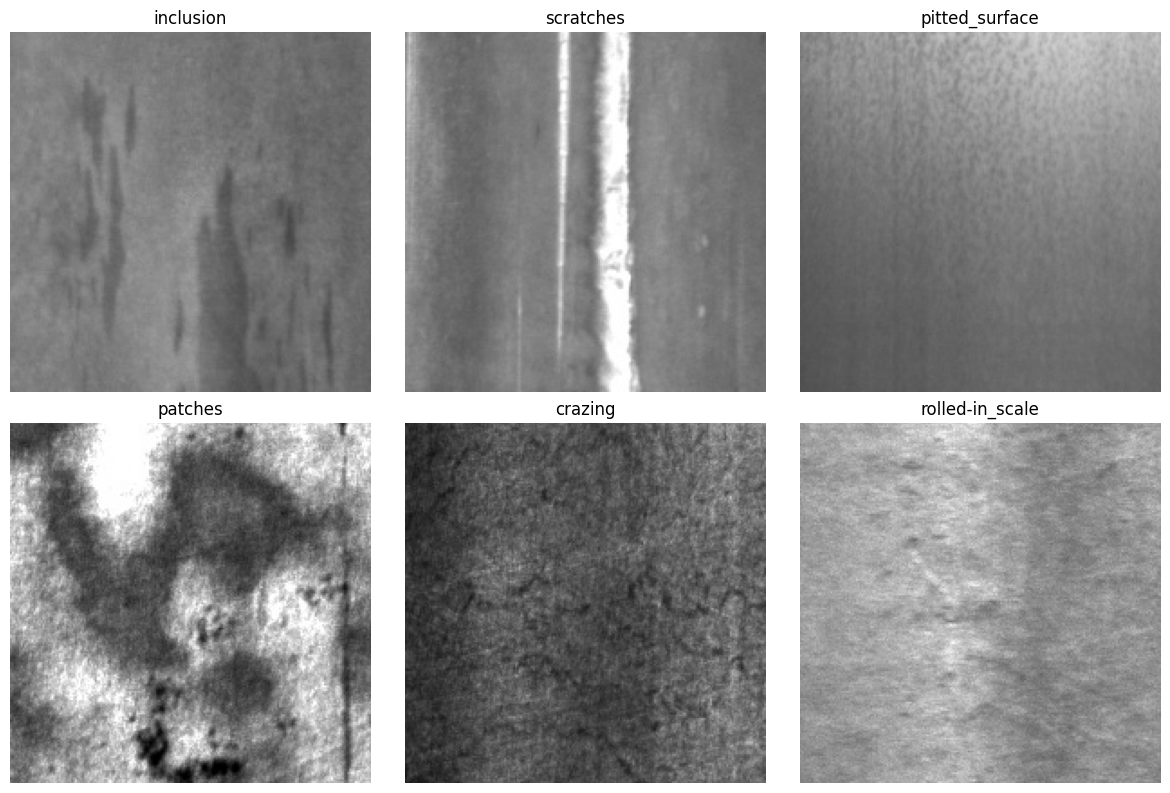

In [ ]:
import matplotlib.pyplot as plt
import random

class_names = os.listdir(TRAIN_PATH)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, class_name in zip(axes.flat, class_names):

    class_path = os.path.join(TRAIN_PATH, class_name)

    images = os.listdir(class_path)
    image_name = random.choice(images)

    img = Image.open(
        os.path.join(class_path, image_name)
    )

    ax.imshow(img)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

class_names = sorted(os.listdir(TRAIN_PATH))

encoder = LabelEncoder()
encoder.fit(class_names)

class_to_label = {}
for class_name in class_names:
    class_to_label[class_name] = int(encoder.transform([class_name])[0])

print(class_to_label)

{'crazing': 0, 'inclusion': 1, 'patches': 2, 'pitted_surface': 3, 'rolled-in_scale': 4, 'scratches': 5}


In [ ]:
import os

duplicate_path = "/kaggle/input/neu-surface-defect-database/NEU-DET/train/images/patches/patches_105.jpg"

print(os.path.exists(duplicate_path))

True


In [ ]:
import numpy as np
from PIL import Image
import os

def load_images(dataset_path, class_to_label):

    X = []
    y = []

    for class_name, label in class_to_label.items():

        class_path = os.path.join(dataset_path, class_name)

        for filename in sorted(os.listdir(class_path)):

            image_path = os.path.join(class_path, filename)

            if filename == "patches_105.jpg" and class_name == "patches":
                continue

            try:
                img = Image.open(image_path).convert("RGB")

                img_array = np.array(img, dtype=np.float32)

                X.append(img_array)
                y.append(label)

            except Exception as e:
                print("Error:", image_path, e)

    X = np.array(X) / 255.0
    y = np.array(y)

    return X, y

In [ ]:
X_train, y_train = load_images(
    TRAIN_PATH,
    class_to_label
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("Min:", X_train.min())
print("Max:", X_train.max())

X_train: (1439, 200, 200, 3)
y_train: (1439,)
Min: 0.0
Max: 1.0


In [ ]:
X_val, y_val = load_images(
    VAL_PATH,
    class_to_label
)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("Min:", X_val.min())
print("Max:", X_val.max())

X_val: (360, 200, 200, 3)
y_val: (360,)
Min: 0.0
Max: 1.0


In [ ]:
import pandas as pd

distribution = pd.DataFrame({
    "Class": list(class_to_label.keys()),
    "Train": [
        np.sum(y_train == label)
        for label in class_to_label.values()
    ],
    "Validation": [
        np.sum(y_val == label)
        for label in class_to_label.values()
    ]
})

print(distribution)

             Class  Train  Validation
0          crazing    240          60
1        inclusion    240          60
2          patches    239          60
3   pitted_surface    240          60
4  rolled-in_scale    240          60
5        scratches    240          60


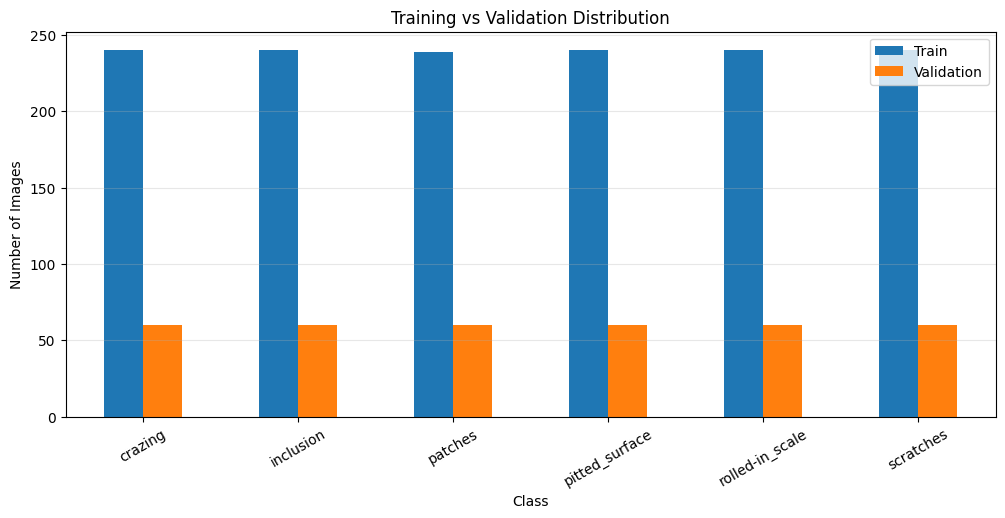

In [ ]:
import matplotlib.pyplot as plt

distribution.set_index("Class").plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Training vs Validation Distribution")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
import tensorflow as tf

augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip("horizontal"),

    tf.keras.layers.RandomRotation(0.05),

    tf.keras.layers.RandomZoom(
        height_factor=(-0.05, 0.05),
        width_factor=(-0.05, 0.05)
    ),

    tf.keras.layers.RandomContrast(0.1)

])

In [ ]:
sample = X_train[0]

augmented = augmentation(
    tf.expand_dims(sample, axis=0),
    training=True
)

augmented = tf.clip_by_value(
    augmented, 0.0, 1.0
)

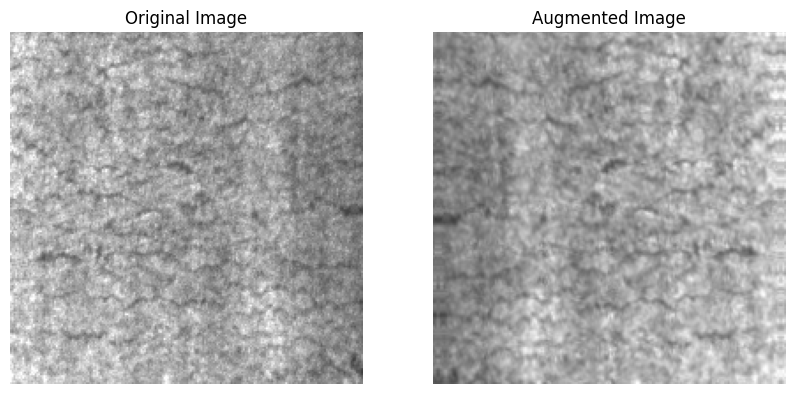

In [ ]:

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(sample)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(augmented[0].numpy())
plt.title("Augmented Image")
plt.axis("off")

plt.show()

In [ ]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)

print("Train range:", X_train.min(), X_train.max())
print("Validation range:", X_val.min(), X_val.max())

Training: (1439, 200, 200, 3) (1439,)
Validation: (360, 200, 200, 3) (360,)
Train range: 0.0 1.0
Validation range: 0.0 1.0


In [ ]:
import hashlib

def get_image_hashes(dataset_path):

    image_hashes = {}

    for class_name in class_to_label:

        class_path = os.path.join(dataset_path, class_name)

        for filename in os.listdir(class_path):

            image_path = os.path.join(class_path, filename)

            try:
                with Image.open(image_path) as img:

                    img = img.convert("RGB")

                    image_array = np.array(img)

                    image_hash = hashlib.md5(
                        image_array.tobytes()
                    ).hexdigest()

                    image_hashes.setdefault(
                        image_hash, []
                    ).append({
                        "path": image_path,
                        "class": class_name
                    })

            except Exception as e:
                print("Error:", image_path, e)

    return image_hashes


train_hashes = get_image_hashes(TRAIN_PATH)
val_hashes = get_image_hashes(VAL_PATH)

common_hashes = set(train_hashes) & set(val_hashes)

print("Train unique images:", len(train_hashes))
print("Validation unique images:", len(val_hashes))
print("Cross-dataset duplicates:", len(common_hashes))

Train unique images: 1439
Validation unique images: 360
Cross-dataset duplicates: 0


In [ ]:
import pandas as pd

# Dataset information
print("Dataset Audit")
print("-" * 40)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

print("\nClass names:")
print(class_names)

print("\nClass distribution:")

for class_name, label in class_to_label.items():
    train_count = np.sum(y_train == label)
    val_count = np.sum(y_val == label)

    print(
        f"{class_name}: "
        f"Train = {train_count}, "
        f"Validation = {val_count}"
    )

print("\nData types:")
print("X_train dtype:", X_train.dtype)
print("y_train dtype:", y_train.dtype)

print("\nMissing values:")
print("X_train:", np.isnan(X_train).sum())
print("y_train:", pd.isna(y_train).sum())
print("X_val:", np.isnan(X_val).sum())
print("y_val:", pd.isna(y_val).sum())

print("\nUnique target values:")
print(np.unique(y_train))

Dataset Audit
----------------------------------------
Training shape: (1439, 200, 200, 3)
Validation shape: (360, 200, 200, 3)

Class names:
['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']

Class distribution:
crazing: Train = 240, Validation = 60
inclusion: Train = 240, Validation = 60
patches: Train = 239, Validation = 60
pitted_surface: Train = 240, Validation = 60
rolled-in_scale: Train = 240, Validation = 60
scratches: Train = 240, Validation = 60

Data types:
X_train dtype: float32
y_train dtype: int64

Missing values:
X_train: 0
y_train: 0
X_val: 0
y_val: 0

Unique target values:
[0 1 2 3 4 5]


In [ ]:
indices = [0, 239, 240, 479, 480, 719, 720, 959, 960, 1199, 1200, 1438]
# Before Encoding
y_train_original = encoder.inverse_transform(y_train)

print("Before Encoding:")
print(y_train_original[indices])

# After Encoding
print("\nAfter Encoding:")
print(y_train[indices])

# Mapping
print("\nEncoding Mapping:")
for class_name, label in class_to_label.items():
    print(f"{class_name} -> {label}")

Before Encoding:
['crazing' 'crazing' 'inclusion' 'inclusion' 'patches' 'pitted_surface'
 'pitted_surface' 'rolled-in_scale' 'rolled-in_scale' 'scratches'
 'scratches' 'scratches']

After Encoding:
[0 0 1 1 2 3 3 4 4 5 5 5]

Encoding Mapping:
crazing -> 0
inclusion -> 1
patches -> 2
pitted_surface -> 3
rolled-in_scale -> 4
scratches -> 5


In [ ]:
# Test unseen category
try:
    encoder.transform(["new_defect"])
except ValueError as e:
    print("Unseen category detected!")
    print(e)

Unseen category detected!
y contains previously unseen labels: np.str_('new_defect')




*   Handling Known Categories: LabelEncoder only handles the categories it learned during the fit phase.
*   Unseen Categories: It cannot automatically transform new, unknown categories.


In [ ]:
# Final validation

print("Training validation:")
print("Images:", len(X_train))
print("Labels:", len(y_train))
print("Numeric labels:", np.issubdtype(y_train.dtype, np.number))
print("Missing labels:", np.isnan(y_train).sum())
print("Unique labels:", np.unique(y_train))

print("\nValidation set:")
print("Images:", len(X_val))
print("Labels:", len(y_val))
print("Numeric labels:", np.issubdtype(y_val.dtype, np.number))
print("Missing labels:", np.isnan(y_val).sum())
print("Unique labels:", np.unique(y_val))

print("\nSame encoding classes:",
      np.array_equal(np.unique(y_train), np.unique(y_val)))

Training validation:
Images: 1439
Labels: 1439
Numeric labels: True
Missing labels: 0
Unique labels: [0 1 2 3 4 5]

Validation set:
Images: 360
Labels: 360
Numeric labels: True
Missing labels: 0
Unique labels: [0 1 2 3 4 5]

Same encoding classes: True


In [ ]:
from sklearn.model_selection import train_test_split

X_train_new, X_test, y_train_new, y_test = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [ ]:
print("New Training:", X_train_new.shape, y_train_new.shape)
print("Test:", X_test.shape, y_test.shape)
print("Original Validation:", X_val.shape, y_val.shape)

New Training: (1151, 200, 200, 3) (1151,)
Test: (288, 200, 200, 3) (288,)
Original Validation: (360, 200, 200, 3) (360,)


In [ ]:
import numpy as np

for class_name, label in class_to_label.items():
    train_count = np.sum(y_train_new == label)
    test_count = np.sum(y_test == label)

    print(
        f"{class_name}: "
        f"Train = {train_count}, "
        f"Test = {test_count}"
    )

crazing: Train = 192, Test = 48
inclusion: Train = 192, Test = 48
patches: Train = 191, Test = 48
pitted_surface: Train = 192, Test = 48
rolled-in_scale: Train = 192, Test = 48
scratches: Train = 192, Test = 48


In [ ]:
from skimage.feature import hog
from skimage.color import rgb2gray

def extract_hog(images):
    features = []

    for img in images:
        if img.ndim == 3 and img.shape[-1] == 3:
            img = rgb2gray(img)
        elif img.ndim == 3 and img.shape[-1] == 1:
            img = img.squeeze()

        feature = hog(
            img,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys',
            feature_vector=True
        )

        features.append(feature)

    return np.array(features, dtype=np.float32)

X_train_hog = extract_hog(X_train_new)
X_val_hog = extract_hog(X_val)
X_test_hog = extract_hog(X_test)


print("Train HOG shape:", X_train_hog.shape)
print("Validation HOG shape:", X_val_hog.shape)
print("Test HOG shape:", X_test_hog.shape)

Train HOG shape: (1151, 20736)
Validation HOG shape: (360, 20736)
Test HOG shape: (288, 20736)


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf'))
])

param_grid = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': ['scale', 0.001, 0.0001]
}

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_hog, y_train_new)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1:", grid_search.best_score_)

best_svm = grid_search.best_estimator_

y_val_pred = best_svm.predict(X_val_hog)

from sklearn.metrics import accuracy_score, classification_report

print("\nValidation Accuracy:",
      accuracy_score(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Parameters: {'svm__C': 10, 'svm__gamma': 'scale'}
Best Cross-Validation F1: 0.7971747824592069

Validation Accuracy: 0.8305555555555556

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.95      0.86        60
           1       0.92      0.78      0.85        60
           2       0.73      0.53      0.62        60
           3       0.71      0.73      0.72        60
           4       1.00      1.00      1.00        60
           5       0.83      0.98      0.90        60

    accuracy                           0.83       360
   macro avg       0.83      0.83      0.82       360
weighted avg       0.83      0.83      0.82       360



## Under Fitting **SVM**

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm_underfit = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(
        kernel='rbf',
        C=0.001,
        gamma=0.00001
    ))
])

svm_underfit.fit(X_train_hog, y_train_new)

Pipeline(steps=[('scaler', StandardScaler()),
                ('svm', SVC(C=0.001, gamma=1e-05))])

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

# Predictions
train_pred = svm_underfit.predict(X_train_hog)
val_pred = svm_underfit.predict(X_val_hog)

# Accuracy
train_acc = accuracy_score(y_train_new, train_pred)
val_acc = accuracy_score(y_val, val_pred)

# Macro F1
train_f1 = f1_score(y_train_new, train_pred, average='macro')
val_f1 = f1_score(y_val, val_pred, average='macro')

print("SVM - Underfitting")
print("--------------------------")

print(f"Train Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")

print(f"Train Macro F1: {train_f1:.4f}")
print(f"Validation Macro F1: {val_f1:.4f}")

SVM - Underfitting
--------------------------
Train Accuracy: 0.6351
Validation Accuracy: 0.5250
Train Macro F1: 0.5782
Validation Macro F1: 0.4215


## Over Fitting **SVM**

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm_overfit = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(
        kernel='rbf',
        C=10000,
        gamma=0.01
    ))
])

svm_overfit.fit(X_train_hog, y_train_new)

Pipeline(steps=[('scaler', StandardScaler()),
                ('svm', SVC(C=10000, gamma=0.01))])

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

train_pred = svm_overfit.predict(X_train_hog)
val_pred = svm_overfit.predict(X_val_hog)

train_acc = accuracy_score(y_train_new, train_pred)
val_acc = accuracy_score(y_val, val_pred)

train_f1 = f1_score(y_train_new, train_pred, average='macro')
val_f1 = f1_score(y_val, val_pred, average='macro')

print("SVM - Overfitting")
print("--------------------------")

print(f"Train Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")

print(f"Train Macro F1: {train_f1:.4f}")
print(f"Validation Macro F1: {val_f1:.4f}")

SVM - Overfitting
--------------------------
Train Accuracy: 1.0000
Validation Accuracy: 0.5389
Train Macro F1: 1.0000
Validation Macro F1: 0.4828


# **Random Forest**

Train Accuracy: 1.0
Validation Accuracy: 0.6

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.93      0.75        60
           1       0.73      0.73      0.73        60
           2       0.60      0.35      0.44        60
           3       0.68      0.53      0.60        60
           4       0.52      1.00      0.69        60
           5       0.21      0.05      0.08        60

    accuracy                           0.60       360
   macro avg       0.56      0.60      0.55       360
weighted avg       0.56      0.60      0.55       360



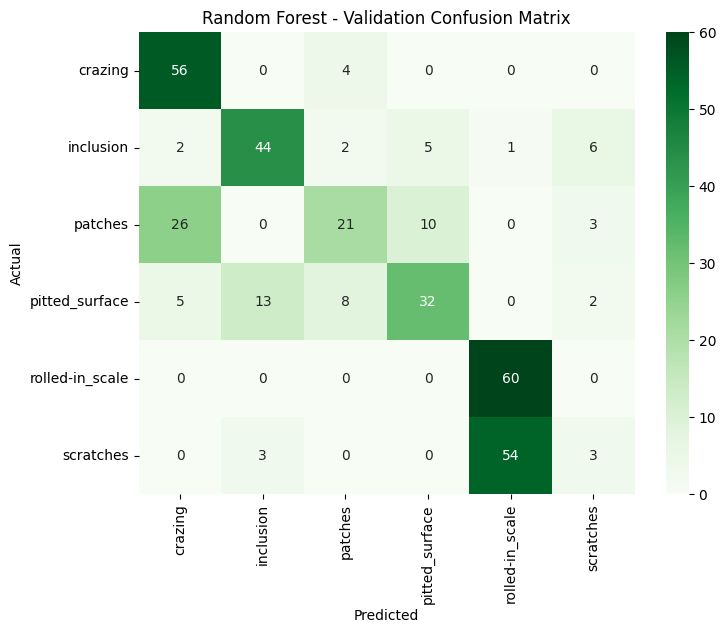

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_hog, y_train_new)

y_train_pred_rf = rf_model.predict(X_train_hog)
y_val_pred_rf = rf_model.predict(X_val_hog)

print("Train Accuracy:",
      accuracy_score(y_train_new, y_train_pred_rf))

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_rf))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf))

cm_rf = confusion_matrix(y_val, y_val_pred_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Validation Confusion Matrix")
plt.show()

## Under Fitting **Random_Forest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_underfit = RandomForestClassifier(
    n_estimators=5,
    max_depth=1,
    min_samples_split=20,
    min_samples_leaf=10,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

rf_underfit.fit(X_train_hog, y_train_new)

RandomForestClassifier(max_depth=1, min_samples_leaf=10, min_samples_split=20,
                       n_estimators=5, n_jobs=-1, random_state=42)

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

train_pred = rf_underfit.predict(X_train_hog)
val_pred = rf_underfit.predict(X_val_hog)

train_acc = accuracy_score(y_train_new, train_pred)
val_acc = accuracy_score(y_val, val_pred)

train_f1 = f1_score(y_train_new, train_pred, average='macro')
val_f1 = f1_score(y_val, val_pred, average='macro')

print("Random Forest - Underfitting")
print("--------------------------")

print(f"Train Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")

print(f"Train Macro F1: {train_f1:.4f}")
print(f"Validation Macro F1: {val_f1:.4f}")

Random Forest - Underfitting
--------------------------
Train Accuracy: 0.3284
Validation Accuracy: 0.2278
Train Macro F1: 0.2294
Validation Macro F1: 0.1467


## Over Fitting **Random_Forest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_overfit = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

rf_overfit.fit(X_train_hog, y_train_new)

RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=42)

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

train_pred = rf_overfit.predict(X_train_hog)
val_pred = rf_overfit.predict(X_val_hog)

train_acc = accuracy_score(y_train_new, train_pred)
val_acc = accuracy_score(y_val, val_pred)

train_f1 = f1_score(y_train_new, train_pred, average='macro')
val_f1 = f1_score(y_val, val_pred, average='macro')

print("Random Forest - Overfitting")
print("--------------------------")

print(f"Train Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")

print(f"Train Macro F1: {train_f1:.4f}")
print(f"Validation Macro F1: {val_f1:.4f}")

Random Forest - Overfitting
--------------------------
Train Accuracy: 1.0000
Validation Accuracy: 0.5917
Train Macro F1: 1.0000
Validation Macro F1: 0.5326


# **KNN**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_jobs=-1))
])

param_grid_knn = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan']
}

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid_knn,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=2
)

knn_search.fit(X_train_hog, y_train_new)

print("Best Parameters:", knn_search.best_params_)
print("Best Cross-Validation F1:", knn_search.best_score_)

best_knn = knn_search.best_estimator_

y_val_pred_knn = best_knn.predict(X_val_hog)

from sklearn.metrics import accuracy_score, classification_report

print("\nValidation Accuracy:",
      accuracy_score(y_val, y_val_pred_knn))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_knn))

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best Parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 3, 'knn__weights': 'distance'}
Best Cross-Validation F1: 0.6114620620009384

Validation Accuracy: 0.625

Classification Report:
              precision    recall  f1-score   support

           0       0.48      0.95      0.64        60
           1       0.88      0.38      0.53        60
           2       0.49      0.42      0.45        60
           3       0.85      0.48      0.62        60
           4       0.67      1.00      0.80        60
           5       0.76      0.52      0.61        60

    accuracy                           0.62       360
   macro avg       0.69      0.62      0.61       360
weighted avg       0.69      0.62      0.61       360



# Under Fitting **KNN**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_predict

knn_underfit = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(
        n_neighbors=150,
        weights='uniform',
        metric='manhattan',
        n_jobs=-1
    ))
])

train_pred = cross_val_predict(
    knn_underfit,
    X_train_hog,
    y_train_new,
    cv=3
)

knn_underfit.fit(X_train_hog, y_train_new)

val_pred = knn_underfit.predict(X_val_hog)

print("KNN - Underfitting")
print("--------------------------")

print("Training Accuracy:", accuracy_score(y_train_new, train_pred))
print("Validation Accuracy:", accuracy_score(y_val, val_pred))

print("Training Macro F1:", f1_score(y_train_new, train_pred, average='macro'))
print("Validation Macro F1:", f1_score(y_val, val_pred, average='macro'))

KNN - Underfitting
--------------------------
Training Accuracy: 0.35447437011294525
Validation Accuracy: 0.3861111111111111
Training Macro F1: 0.25421267396013536
Validation Macro F1: 0.2735116286113291


## Over Fitting **KNN**

In [ ]:
knn_overfit = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(
        n_neighbors=1,
        weights='uniform',
        metric='euclidean',
        n_jobs=-1
    ))
])

In [ ]:
knn_overfit.fit(X_train_hog, y_train_new)

train_pred = knn_overfit.predict(X_train_hog)
val_pred = knn_overfit.predict(X_val_hog)

print("KNN - Overfitting")
print("-------------------------")

print("Training Accuracy:",
      accuracy_score(y_train_new, train_pred))

print("Validation Accuracy:",
      accuracy_score(y_val, val_pred))

print("Training Macro F1:",
      f1_score(y_train_new, train_pred, average='macro'))

print("Validation Macro F1:",
      f1_score(y_val, val_pred, average='macro'))

KNN - Overfitting
-------------------------
Training Accuracy: 1.0
Validation Accuracy: 0.5722222222222222
Training Macro F1: 1.0
Validation Macro F1: 0.5465975917456616


# **Compare**

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

models = {
    'SVM': best_svm,
    'Random Forest': rf_model,
    'KNN': best_knn
}

final_results = {}

for name, model in models.items():

    y_pred = model.predict(X_test_hog)

    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')

    final_results[name] = {
        'Accuracy': accuracy,
        'Macro F1': macro_f1
    }

    print("=" * 50)
    print(name)
    print("=" * 50)

    print("Test Accuracy:", accuracy)
    print("Test Macro F1:", macro_f1)

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

SVM
Test Accuracy: 0.8229166666666666
Test Macro F1: 0.82049786108899

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.96      0.93        48
           1       0.78      0.90      0.83        48
           2       0.78      0.67      0.72        48
           3       0.68      0.67      0.67        48
           4       1.00      1.00      1.00        48
           5       0.78      0.75      0.77        48

    accuracy                           0.82       288
   macro avg       0.82      0.82      0.82       288
weighted avg       0.82      0.82      0.82       288


Confusion Matrix:
[[46  0  2  0  0  0]
 [ 0 43  0  5  0  0]
 [ 3  0 32  8  0  5]
 [ 1  4  6 32  0  5]
 [ 0  0  0  0 48  0]
 [ 1  8  1  2  0 36]]
Random Forest
Test Accuracy: 0.7152777777777778
Test Macro F1: 0.7010485309070567

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.98      0.80        48
  